Libraries imported successfully.
Using Colab cache for faster access to the 'dog-vs-cat' dataset.
Classes detected: ['cat', 'dog']
Found 1000 files belonging to 2 classes.
Using 800 files for training.
Found 1000 files belonging to 2 classes.
Using 200 files for validation.


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_4 (Sequential)       │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │    18,940,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,034,177 (72.61 MB)

 Trainable params: 19,034,177 (72.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 68s 2s/step - accuracy: 0.5713 - loss: 0.7631 - val_accuracy: 0.7800 - val_loss: 0.5119
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 62s 2s/step - accuracy: 0.7650 - loss: 0.4929 - val_accuracy: 0.8550 - val_loss: 0.3392
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 68s 3s/step - accuracy: 0.8075 - loss: 0.4094 - val_accuracy: 0.7100 - val_loss: 0.8423
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 82s 3s/step - accuracy: 0.8338 - loss: 0.4399 - val_accuracy: 0.9450 - val_loss: 0.1975
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step - accuracy: 0.8988 - loss: 0.2663 - val_accuracy: 0.9700 - val_loss: 0.1083
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 62s 2s/step - accuracy: 0.9150 - loss: 0.2197 - val_accuracy: 0.9250 - val_loss: 0.1814
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 82s 2s/step - accuracy: 0.9475 - loss: 0.1651 - val_accuracy: 0.9750 - val_loss: 0.1020
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 64s 2s/step - accuracy: 0.9600 - loss: 0.1343 - val_accuracy: 0.9700 - val_loss:

Saving Screenshot 2026-10-25 104202.png to Screenshot 2026-10-25 104202.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step
Raw prediction score: 0.3816


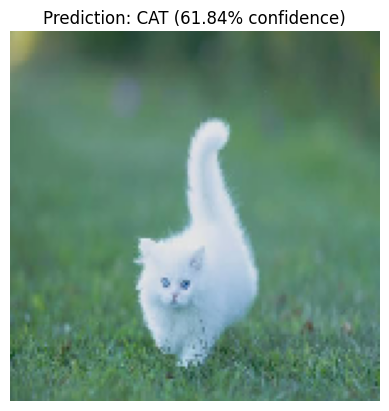

In [3]:
import os
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np

IMG_HEIGHT = 150
IMG_WIDTH = 150
BATCH_SIZE = 32

print("Libraries imported successfully.")

!pip install -q kagglehub
import kagglehub

path = kagglehub.dataset_download("anthonytherrien/dog-vs-cat")
train_dir = os.path.join(path, 'animals')

class_names = sorted(os.listdir(train_dir))
print("Classes detected:", class_names)

train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE
)

val_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE
)

normalization_layer = layers.Rescaling(1./255)
train_dataset = train_dataset.map(lambda x, y: (normalization_layer(x), y))
val_dataset = val_dataset.map(lambda x, y: (normalization_layer(x), y))

train_dataset = train_dataset.prefetch(buffer_size=tf.data.AUTOTUNE)
val_dataset = val_dataset.prefetch(buffer_size=tf.data.AUTOTUNE)

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
])

def build_robust_three_layer_cnn():
    model = models.Sequential([
        layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
        data_augmentation,

        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(1, activation='sigmoid') # Binary output: 0 = cat, 1 = dog
    ])
    return model

model = build_robust_three_layer_cnn()
model.summary()

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    train_dataset,
    epochs=10,
    validation_data=val_dataset
)

from google.colab import files

def predict_single_image(image_path):
    img = tf.keras.utils.load_img(image_path, target_size=(IMG_HEIGHT, IMG_WIDTH))
    img_array = tf.keras.utils.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0) / 255.0

    prediction = model.predict(img_array)[0][0]
    print(f"Raw prediction score: {prediction:.4f}")

    plt.imshow(img)
    plt.axis('off')
    # Class index 0 is 'cat', class index 1 is 'dog'
    if prediction >= 0.5:
        confidence = prediction * 100
        plt.title(f"Prediction: DOG ({confidence:.2f}% confidence)")
    else:
        confidence = (1 - prediction) * 100
        plt.title(f"Prediction: CAT ({confidence:.2f}% confidence)")

    plt.show()

uploaded = files.upload()
image_filename = list(uploaded.keys())[0]
predict_single_image(image_filename)